# Gaussian processes: inference on $f$ and prediction at $x^\star$
Model: $y_i=f(x_i)+\varepsilon_i,\ \varepsilon_i\sim\mathcal N(0,\sigma_n^2)$, prior $f\sim\mathrm{GP}(0,k)$.

**Example 1** is linear regression (checked against Bayesian linear regression, BLR). **Example 2** is a nonlinear function with a Gaussian kernel.

## Example 1: linear data
Data from $y=0.5+0.8x+\varepsilon$, with features $\phi(x)=[1,x]$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
sigma_n, sigma_p = 0.3, 2.0
w_true = np.array([0.5, 0.8])
n = 15
x = np.sort(rng.uniform(-2, 2, n))
X = np.c_[np.ones(n), x]                       
y = X @ w_true + sigma_n * rng.standard_normal(n)
x_new = np.linspace(-5, 5, 200)
X_new = np.c_[np.ones_like(x_new), x_new]

### Bayesian linear regression
$\Lambda_1^{-1}=\sigma_n^{-2}X^\top X+\sigma_p^{-2}I,\quad \mu=\sigma_n^{-2}\Lambda_1X^\top y$,
predictive $f(\tilde x)\sim\mathcal N(\mu^\top\tilde x,\ \tilde x^\top\Lambda_1\tilde x)$.

In [3]:
def blr_posterior(X, y, sigma_n, sigma_p):
    Lam1 = np.linalg.inv(X.T @ X / sigma_n**2 + np.eye(X.shape[1]) / sigma_p**2)
    return Lam1 @ X.T @ y / sigma_n**2, Lam1

def blr_predict(X_new, mu, Lam1):
    return X_new @ mu, np.einsum("ij,jk,ik->i", X_new, Lam1, X_new)

mu_w, Lam1 = blr_posterior(X, y, sigma_n, sigma_p)
blr_mean, blr_var = blr_predict(X_new, mu_w, Lam1)
print("posterior mean of w:", mu_w, "(true", w_true, ")")

posterior mean of w: [0.49663678 0.8018908 ] (true [0.5 0.8] )


### GP: the two parts
**Part 1, inference on $f_A$ at the training inputs** $A=x_{1:n}$ (with $K=K_{AA}$):
$$\mu=\mu_{AA}+K(K+\sigma_n^2I)^{-1}(y-\mu_{AA}),\qquad \Lambda=K-K(K+\sigma_n^2I)^{-1}K$$

**Part 2, prediction at $x^\star$** (with $k_\star=k_{x^\star,A}$):
$$\mu'(x^\star)=\mu^\star+k_\star^\top(K+\sigma_n^2I)^{-1}(y-\mu_{AA}),\qquad k'(x^\star,x^\star)=k(x^\star,x^\star)-k_\star^\top(K+\sigma_n^2I)^{-1}k_\star$$
and $y^\star$ has variance $k'(x^\star,x^\star)+\sigma_n^2$.

In [4]:
def gp_inference_at_A(kern, xA, y, sigma_n):
    """Part 1: posterior N(mu, Lambda) of f_A at the training inputs (zero prior mean)."""
    K = kern(xA, xA)
    A = K + sigma_n**2 * np.eye(len(xA))
    return K @ np.linalg.solve(A, y), K - K @ np.linalg.solve(A, K)

def gp_predict(kern, xA, y, x_star, sigma_n):
    """Part 2: mu'(x*) and k'(x*,x*) at new inputs (zero prior mean)."""
    A = kern(xA, xA) + sigma_n**2 * np.eye(len(xA))
    Ks = kern(xA, x_star)                                   # columns are k_star
    mean = Ks.T @ np.linalg.solve(A, y)
    var = np.diag(kern(x_star, x_star)) - np.sum(Ks * np.linalg.solve(A, Ks), axis=0)
    return mean, var

def plot_fit(kern, xA, y, x_star, sigma_n, f_true, title, mu_A, Lam_A):
    mean, var = gp_predict(kern, xA, y, x_star, sigma_n)
    sd_f, sd_y = np.sqrt(var), np.sqrt(var + sigma_n**2)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.fill_between(x_star, mean - 1.96*sd_y, mean + 1.96*sd_y, color="C0", alpha=0.15, label=r"95% for $y^\star$")
    ax.fill_between(x_star, mean - 1.96*sd_f, mean + 1.96*sd_f, color="C0", alpha=0.35, label=r"95% for $f^\star$")
    ax.plot(x_star, f_true(x_star), "k--", lw=1.2, label="true $f$")
    ax.plot(x_star, mean, "C0", lw=2, label=r"$\mu'(x^\star)$ (Part 2)")
    ax.errorbar(xA, mu_A, yerr=1.96*np.sqrt(np.diag(Lam_A)), fmt="D", color="C3", ms=4, capsize=2,
                label=r"$f_A\mid y$ (Part 1)")
    ax.plot(xA, y, "o", color="k", ms=4, alpha=0.6, label="data $y$")
    ax.set_title(title, fontsize=10); ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False, fontsize=8); plt.tight_layout(); plt.show()
    return mean, var

### Example 1 with the linear kernel $k(x,x')=\sigma_p^2\,\phi(x)^\top\phi(x')=\sigma_p^2(1+xx')$

Part 1 vs BLR:  max|mu - X mu_w| = 2.5e-14,  max|Lambda - X Lam1 X'| = 7.3e-15


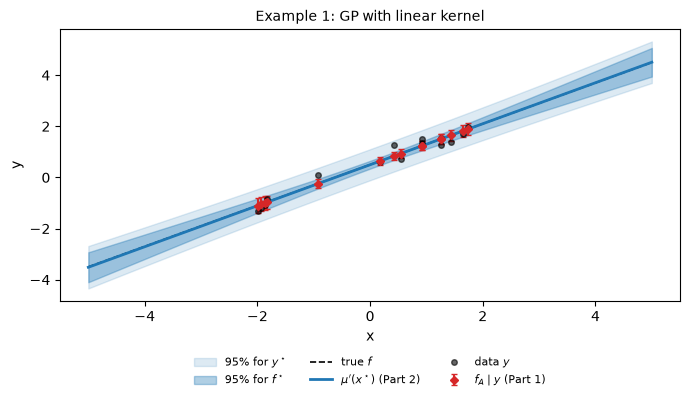

Part 2 vs BLR:  max|mean diff| = 7.1e-14,  max|var diff| = 3.7e-14


In [5]:
k_lin = lambda a, b: sigma_p**2 * (1 + a[:, None] * b[None, :])

mu_A, Lam_A = gp_inference_at_A(k_lin, x, y, sigma_n)                       # Part 1
print("Part 1 vs BLR:  max|mu - X mu_w| = %.1e,  max|Lambda - X Lam1 X'| = %.1e" %
      (np.abs(mu_A - X @ mu_w).max(), np.abs(Lam_A - X @ Lam1 @ X.T).max()))

gp_mean, gp_var = plot_fit(k_lin, x, y, x_new, sigma_n, lambda t: 0.5 + 0.8*t,
                           "Example 1: GP with linear kernel", mu_A, Lam_A)                  # Part 2
print("Part 2 vs BLR:  max|mean diff| = %.1e,  max|var diff| = %.1e" %
      (np.abs(gp_mean - blr_mean).max(), np.abs(gp_var - blr_var).max()))

## Example 2: nonlinear function, Gaussian kernel
Data from $y=\sin x+\varepsilon$, with the Gaussian kernel $k(x,x')=\exp\!\big(-\tfrac{(x-x')^2}{2\ell^2}\big)$, $\ell=1$, zero mean.

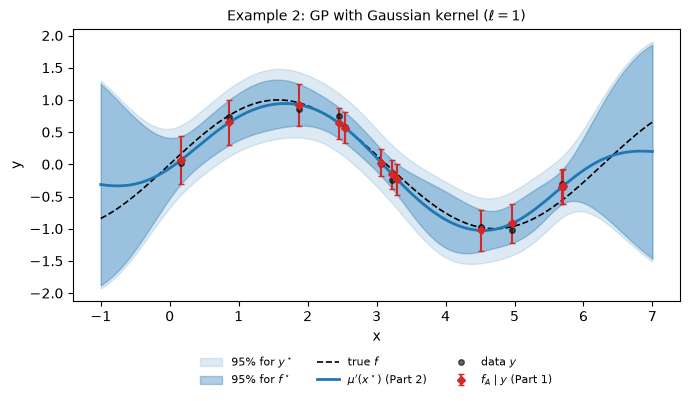

In [6]:
rng2 = np.random.default_rng(1)
sigma_n2, ell = 0.2, 1.0
n2 = 12
x2 = np.sort(rng2.uniform(0, 6, n2))
y2 = np.sin(x2) + sigma_n2 * rng2.standard_normal(n2)
x2_new = np.linspace(-1, 7, 300)

k_rbf = lambda a, b: np.exp(-0.5 * (a[:, None] - b[None, :])**2 / ell**2)

mu_A2, Lam_A2 = gp_inference_at_A(k_rbf, x2, y2, sigma_n2)                  # Part 1
_ = plot_fit(k_rbf, x2, y2, x2_new, sigma_n2, np.sin,
             r"Example 2: GP with Gaussian kernel ($\ell=1$)", mu_A2, Lam_A2)               # Part 2